# Hari 1, Sesi 6: Data Panel dan Model Volatilitas GARCH

**Durasi:** 90 menit

Dua topik dari Pertemuan 14 dan 15.

**Panel.** Struktur datanya individu x waktu. Pertanyaan utamanya: model
mana yang cocok, Common Effect (CEM), Fixed Effect (FEM), atau Random
Effect (REM)? Sesi ini mempraktikkan Chow dan Hausman. Uji LM disebut
sebagai pilihan tambahan untuk membandingkan CEM dengan REM.

**GARCH.** Data keuangan punya pola "tenang mengelompok, gejolak
mengelompok" (volatility clustering). OLS tidak bisa menangkap ini karena
GARCH memodelkan varians, bukan rata-rata.



**Posisi dalam alur workshop.** Sesi penutup Hari 1: panel menggabungkan
banyak unit dan waktu, GARCH mengganti objek pemodelan dari rata-rata ke
varians. Hari 2 mengulang alur ini sebagai latihan.



## Persiapan: alamat data

Jalankan sel alamat data di bawah. `URL_DATA` menyimpan alamat folder CSV di GitHub;
`pd.read_csv(...)` membaca tabel sesuai nama CSV pada sel kode berikutnya.
Gunakan koneksi internet dan jalankan sel berurutan dengan **Shift + Enter**. Paket `linearmodels` dan `arch` juga dipasang di sini.



## Cara mengikuti notebook ini

Jalankan sel berurutan dengan `Shift + Enter`. Setiap notebook dapat
dimulai sendiri dengan koneksi internet yang aktif. Sel persiapan cukup dijalankan
apa adanya; fokus latihan dimulai saat tabel data muncul.

Baca penjelasan sebelum menjalankan kode, lalu sebutkan arti hasilnya.
Ubah satu hal setiap mencoba: nama kolom pada X, pilihan model, atau nilai prediksi.
Baris `#` adalah catatan. `=` menyimpan hasil dan `==` membandingkan nilai.
Contoh `tabel["kolom"]` berarti memilih satu kolom dari tabel.

Jika muncul error merah, berhenti di sel itu dan baca baris terakhirnya.
Jika ada warning, baca pesannya dan periksa hasil estimasi sebelum lanjut.
Panduan simbol dan contoh tambahan ada di `panduan/01_panduan_pemula.md`.



### Pola pemodelan yang dipakai

`X` adalah tabel fitur dan `y` adalah kolom target. Model utama memakai
scikit-learn: buat model, jalankan `fit(X, y)`, lalu gunakan `predict(X_baru)`.
Koefisien ada pada `coef_` dan intersep pada `intercept_`. Tabel `koefisien_...`
hanya memberi nama kolom agar angka mudah dibaca. `score(X, y)` pada regresi
linear adalah R² pada data yang diberikan; hasil pada data latih belum mengukur
kemampuan memprediksi data baru.

Nama `uji_...` menandai pelengkap statistik untuk p-value, standard error, atau
uji asumsi. Perhitungannya memakai X dan y yang sama. Bagian model khusus diberi
catatan tersendiri ketika scikit-learn belum menyediakan estimatornya.



In [1]:
URL_DATA = "https://raw.githubusercontent.com/akhiyarwaladi/ekonometrika_coding_workshop/main/data/"

print("Alamat data siap. Jalankan sel pembacaan CSV berikutnya.")



Alamat data siap. Jalankan sel pembacaan CSV berikutnya.


In [2]:
%pip install "linearmodels==7.1" "arch==8.0.0" -q



Note: you may need to restart the kernel to use updated packages.


In [3]:
import pandas as pd
from sklearn.dummy import DummyRegressor
import numpy as np
import statsmodels.api as sm
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", palette=["#2F5D50", "#C15937", "#D9A441", "#5B8A8F"])
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold", "font.size": 11})



## Bagian 1: Data panel

Data `panel_gdp.csv`: 10 negara x 5 tahun. GDP dijelaskan FDI dan tenaga
kerja. Pertama, data diubah ke format panel: indeks dua level, entity dan
waktu.



<!-- kamus_variabel:panel_gdp.csv -->

### Kenali data: Panel PDB simulasi

**Data:** `data/panel_gdp.csv`. **Satu baris:** satu negara pada satu tahun.

| Variabel/kolom | Pengertian | Satuan atau kode | Peran |
|---|---|---|---|
| `CountryID` | Kode negara dalam panel simulasi. | Kode 1 sampai 10; bukan nama negara terverifikasi | Penanda, bukan besaran ekonomi |
| `Year` | Tahun kalender pada contoh. | Tahun | Penanda waktu |
| `GDP_Y` | Gross Domestic Product/PDB: besarnya output ekonomi. | Level PDB; skala mata uang tidak dicantumkan | Y: target |
| `FDI_X1` | Foreign Direct Investment: investasi asing langsung. | Level investasi; skala tidak dicantumkan | X: penjelas |
| `Labor_X2` | Labor force: besarnya angkatan kerja. | Skala jumlah tenaga kerja tidak dicantumkan | X: penjelas |

GDP_Y adalah level PDB simulasi; PDB_Growth pada data World Bank adalah pertumbuhan persen. FDI_X1 di sini tidak otomatis mempunyai satuan persen dari PDB.

Sumber definisi: [rujukan data](https://paggalih.github.io/matkul/sem2025-01/ekonometrika/).



In [4]:
gdp = pd.read_csv(URL_DATA + "panel_gdp.csv")
panel = gdp.set_index(["CountryID", "Year"])
panel.head()



GDP_Y  FDI_X1  Labor_X2
CountryID Year                         
1         2019  500.2    45.1     120.5
          2020  480.5    40.2     121.0
          2021  510.3    48.5     122.1
          2022  530.8    52.1     123.5
          2023  550.1    55.0     124.0

In [5]:
from linearmodels.panel import PanelOLS, RandomEffects

y = panel["GDP_Y"]
X = panel[["FDI_X1", "Labor_X2"]]

# Common Effect (semua individu disatukan)
cem = PanelOLS(y, sm.add_constant(X)).fit(cov_type="clustered", cluster_entity=True)
# Catatan: di linearmodels, summary adalah properti, jadi tanpa tanda
# kurung. statsmodels memakai summary() dengan tanda kurung.
print(cem.summary)



                          PanelOLS Estimation Summary                           
Dep. Variable:                  GDP_Y   R-squared:                        0.9934
Estimator:                   PanelOLS   R-squared (Between):              0.9937
No. Observations:                  50   R-squared (Within):               0.9776
Date:                Sat, Oct 24 2026   R-squared (Overall):              0.9934
Time:                        16:52:15   Log-likelihood                   -205.53
Cov. Estimator:             Clustered                                           
                                        F-statistic:                      3560.2
Entities:                          10   P-value                           0.0000
Avg Obs:                       5.0000   Distribution:                    F(2,47)
Min Obs:                       5.0000                                           
Max Obs:                       5.0000   F-statistic (robust):             700.97
                            

In [6]:
# Fixed Effect (tiap negara punya intersep sendiri)
fem = PanelOLS(y, X, entity_effects=True).fit(cov_type="clustered", cluster_entity=True)
print(fem.summary)



                          PanelOLS Estimation Summary                           
Dep. Variable:                  GDP_Y   R-squared:                        0.9787
Estimator:                   PanelOLS   R-squared (Between):              0.9676
No. Observations:                  50   R-squared (Within):               0.9787
Date:                Sat, Oct 24 2026   R-squared (Overall):              0.9676
Time:                        16:52:15   Log-likelihood                   -131.20
Cov. Estimator:             Clustered                                           
                                        F-statistic:                      872.50
Entities:                          10   P-value                           0.0000
Avg Obs:                       5.0000   Distribution:                    F(2,38)
Min Obs:                       5.0000                                           
Max Obs:                       5.0000   F-statistic (robust):             315.69
                            

In [7]:
# Random Effect (perbedaan antarnegara dianggap acak)
rem = RandomEffects(y, sm.add_constant(X)).fit(
    cov_type="clustered", cluster_entity=True
)
print(rem.summary)



                        RandomEffects Estimation Summary                        
Dep. Variable:                  GDP_Y   R-squared:                        0.9844
Estimator:              RandomEffects   R-squared (Between):              0.9936
No. Observations:                  50   R-squared (Within):               0.9786
Date:                Sat, Oct 24 2026   R-squared (Overall):              0.9934
Time:                        16:52:15   Log-likelihood                   -135.58
Cov. Estimator:             Clustered                                           
                                        F-statistic:                      1478.8
Entities:                          10   P-value                           0.0000
Avg Obs:                       5.0000   Distribution:                    F(2,47)
Min Obs:                       5.0000                                           
Max Obs:                       5.0000   F-statistic (robust):             1638.0
                            

### Uji pemilihan model

| Uji | Membandingkan | Kesimpulan |
|---|---|---|
| Chow | CEM vs FEM | p < 0,05 pilih FEM |
| Hausman | FEM vs REM | p < 0,05 pilih FEM |
| LM | CEM vs REM | p < 0,05 pilih REM |

Uji Chow tersedia langsung sebagai `f_pooled` dari model FEM. Hausman
dijalankan dengan fungsi bawaan `hausman()` pada linearmodels 7.1.



In [8]:
print("Uji Chow (poolability F-test):")
print(fem.f_pooled)



Uji Chow (poolability F-test):
Pooled F-statistic
H0: Effects are zero
Statistic: 78.3640
P-value: 0.0000
Distributed: F(9,38)


In [9]:
# Hausman: bandingkan koefisien FEM dan REM.

# Hausman klasik memakai kovarians unadjusted pada sampel yang sama.
# Hasil clustered di atas tetap dipakai untuk pelaporan koefisien dan SE.
fem_uji = PanelOLS(y, X, entity_effects=True).fit()
rem_uji = RandomEffects(y, sm.add_constant(X)).fit()

# sigmamore menyamakan dasar varians galat kedua model memakai estimasi REM.
hausman = rem_uji.hausman(fem_uji, sigmamore=True)
print(hausman)



Hausman specification test
H0: No systematic difference in coefficients between models
Statistic: 0.2906
P-value: 0.8648
Distributed: chi2(2)

Coefficients (b0: consistent under H0 and H1, b1: efficient under H0)
                b0        b1     b0-b1  Std. Err.
FDI_X1    4.239609  4.125691  0.113918   0.236906
Labor_X2  1.789701  2.385314 -0.595613   1.283288


### Membaca hasil pemilihan model

Baca dua hasil pengujian sesuai pertanyaan masing-masing:

- Uji Chow (p = 0,0000) menolak CEM, jadi efek individu nyata.
- Hausman klasik dengan varians galat bersama memberi p sekitar 0,8648.
  Pada taraf 5% maupun 10%, H0 tidak ditolak. REM dapat dipertimbangkan
  jika asumsi efek individu tidak berkorelasi dengan X masuk akal.

Kegagalan menolak H0 bukan bukti REM pasti benar. Laporkan p-value,
jenis kovarians, serta asumsi model. Ingat
bahwa uji klasik ini mengasumsikan struktur galat yang sesuai.



In [10]:
tabel = pd.DataFrame(
    {
        "koefisien": rem.params,
        "std_err": rem.std_errors,
        "p_value": rem.pvalues,
    }
)
tabel.round(4)



,koefisien,std_err,p_value
const,26.9882,16.8291,0.1155
FDI_X1,4.1257,0.2173,0.0000
Labor_X2,2.3853,0.2529,0.0000


### Coba sendiri (5 menit)

Untuk latihan keputusan, misalkan studi lain menghasilkan p Hausman
0,098. Bagaimana keputusan pada taraf 5 persen dan 10 persen?
Angka ini contoh hipotetis, bukan hasil data GDP di atas.

Tulis di sel di bawah, baru buka jawabannya.



In [11]:
# Tulis jawaban singkat Anda di sini



<details><summary>Lihat jawaban</summary>

Pada taraf 5 persen, H0 tidak ditolak; pada 10 persen, H0 ditolak
sehingga mendukung Fixed Effect. Pesannya:
keputusan model bergantung taraf uji, karena itu laporkan p-value
mentahnya, bukan hanya kata 'signifikan'.

</details>



Panel selesai. Sekarang ganti fokus: yang dimodelkan bukan lagi rata-rata,
melainkan varians.

## Bagian 2: GARCH

Data `volatilitas.csv` berisi return saham 50 periode. Pola yang dicari:
volatilitas mengelompok.



<!-- kamus_variabel:volatilitas.csv -->

### Kenali data: Lima deret simulasi volatilitas

**Data:** `data/volatilitas.csv`. **Satu baris:** satu periode simulasi dengan lima contoh deret yang berbeda.

| Variabel/kolom | Pengertian | Satuan atau kode | Peran |
|---|---|---|---|
| `Observation` | Nomor periode simulasi. | Urutan waktu, bukan tanggal kalender | Penanda waktu |
| `Kasus_1_Saham_Return` | Return/perubahan relatif harga saham pada kasus 1. | Pecahan desimal; 0,012 setara 1,2% | Deret yang dianalisis |
| `Kasus_2_Forex_Return` | Return nilai tukar/foreign exchange pada kasus 2. | Pecahan desimal | Deret yang dianalisis |
| `Kasus_3_Kripto_Return` | Return aset kripto pada kasus 3. | Pecahan desimal | Deret yang dianalisis |
| `Kasus_4_Inflasi_MoM` | Perubahan harga dari bulan sebelumnya (month-on-month) pada kasus 4. | Pecahan desimal; 0,002 setara 0,2% | Deret yang dianalisis |
| `Kasus_5_Minyak_Shock` | Guncangan/perubahan harga minyak pada kasus 5. | Skala simulasi; definisi rinci shock tidak dicantumkan | Deret yang dianalisis |

Return pecahan harus dikalikan 100 jika ingin dibaca dalam persen. Kelima kolom adalah kasus terpisah, bukan lima penjelas dalam satu regresi.

Sumber definisi: [rujukan data](https://paggalih.github.io/matkul/sem2025-01/ekonometrika/).



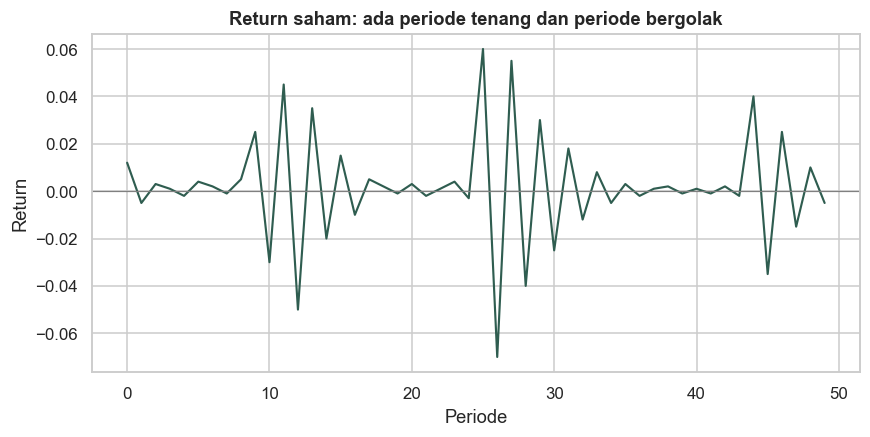

In [12]:
volatilitas = pd.read_csv(URL_DATA + "volatilitas.csv")
ret = volatilitas["Kasus_1_Saham_Return"]

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(ret, lw=1.4)
ax.axhline(0, color="gray", lw=0.8)
ax.set_xlabel("Periode")
ax.set_ylabel("Return")
ax.set_title("Return saham: ada periode tenang dan periode bergolak")
plt.show()



## 2.1 Uji efek ARCH

Langkah di EViews: estimasi persamaan mean dulu (`return c`), lalu
View > Residual Diagnostics > Heteroskedasticity Tests > ARCH. Di
statsmodels namanya `het_arch`.



In [13]:
from statsmodels.stats.diagnostic import het_arch

sampel_model_mean = volatilitas[["Kasus_1_Saham_Return"]].dropna()
X_model_mean = pd.DataFrame({"konstanta": 1}, index=sampel_model_mean.index)
y_model_mean = sampel_model_mean["Kasus_1_Saham_Return"]

model_mean = DummyRegressor(strategy="mean")
model_mean.fit(X_model_mean, y_model_mean)

prediksi_model_mean = pd.Series(
    model_mean.predict(X_model_mean), index=y_model_mean.index
)
residu_model_mean = y_model_mean - prediksi_model_mean
p_arch = het_arch(residu_model_mean, nlags=4)[1]
print(f"ARCH LM test: p-value = {p_arch:.4f}")
print("p < 0,05: ada efek ARCH, lanjut ke GARCH.")



ARCH LM test: p-value = 0.0000
p < 0,05: ada efek ARCH, lanjut ke GARCH.


C:\Users\MyPC PRO\Documents\ekonometrika\.venv\Lib\site-packages\statsmodels\stats\diagnostic.py:997: FutureWarning: acorr_lm currently returns a plain tuple whose length depends on the store argument. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an LMTestResult NamedTuple. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  return acorr_lm(


## 2.2 Estimasi GARCH(1,1)

Persamaan variansnya:

$$\sigma_t^2 = \omega + \alpha \varepsilon_{t-1}^2 + \beta \sigma_{t-1}^2$$

- $\alpha$: reaksi terhadap guncangan baru
- $\beta$: persistensi volatilitas lama
- $\alpha + \beta$ mendekati 1 berarti volatilitas hilang perlahan



In [14]:
from arch import arch_model

model_garch = arch_model(ret, vol="Garch", p=1, q=1, rescale=True)
hasil_garch = model_garch.fit(disp="off")
print(hasil_garch.summary())



                      Constant Mean - GARCH Model Results                       
Dep. Variable:     Kasus_1_Saham_Return   R-squared:                       0.000
Mean Model:               Constant Mean   Adj. R-squared:                  0.000
Vol Model:                        GARCH   Log-Likelihood:               -99.3440
Distribution:                    Normal   AIC:                           206.688
Method:              Maximum Likelihood   BIC:                           214.336
                                          No. Observations:                   50
Date:                  Sat, Oct 24 2026   Df Residuals:                       49
Time:                          16:52:17   Df Model:                            1
                                Mean Model                                
                 coef    std err          t      P>|t|    95.0% Conf. Int.
--------------------------------------------------------------------------
mu             0.3897      0.153      2.544  1

In [15]:
alpha = hasil_garch.params["alpha[1]"]
beta = hasil_garch.params["beta[1]"]
print(f"alpha = {alpha:.4f}")
print(f"beta  = {beta:.4f}")
print(f"alpha + beta = {alpha + beta:.4f}")



alpha = 0.8109
beta  = 0.0000
alpha + beta = 0.8109


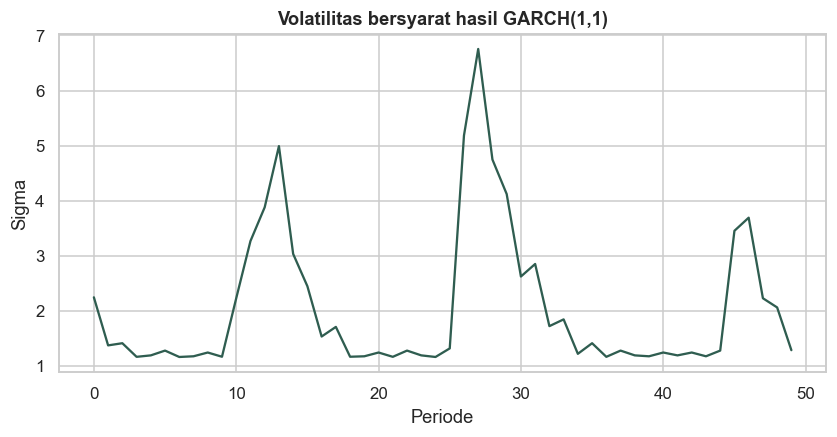

In [16]:
plt.figure(figsize=(9, 4))
plt.plot(hasil_garch.conditional_volatility, lw=1.5)
plt.title("Volatilitas bersyarat hasil GARCH(1,1)")
plt.xlabel("Periode")
plt.ylabel("Sigma")
plt.show()



Perhatikan puncak volatilitas di sekitar periode 26 sampai 30, tepat saat
guncangan besar terjadi. Inilah yang tidak bisa ditangkap OLS.

### Kenapa beta = 0?

Di data simulasi ini, semua reaksi volatilitas masuk lewat guncangan
terbaru saja (murni ARCH), sehingga estimator menempatkan beta di nol.
Di data keuangan nyata, beta biasanya 0,8 sampai 0,9 dan jumlah
alpha + beta mendekati 0,95.

Supaya terlihat bedanya, kita bangkitkan data dengan proses GARCH(1,1)
asli (alpha = 0,12 dan beta = 0,83), lalu estimasi ulang.



In [17]:
# Pustaka arch menyediakan simulasi proses GARCH, sehingga rumus tidak
# perlu diterjemahkan menjadi perulangan sendiri. Seed menjaga contoh tetap sama.
from arch.univariate import ConstantMean, GARCH, Normal

alpha_asli = 0.12
beta_asli = 0.83
proses = ConstantMean(volatility=GARCH(p=1, q=1), distribution=Normal(seed=42))
parameter_asli = [0.0, 0.05, alpha_asli, beta_asli]  # mean, omega, alpha, beta
simulasi = proses.simulate(parameter_asli, nobs=1500)

hasil_sim = arch_model(simulasi["data"], vol="Garch", p=1, q=1).fit(disp="off")
print("Parameter asli: alpha =", alpha_asli, "beta =", beta_asli)
print("Parameter estimasi:")
print(hasil_sim.params)



Parameter asli: alpha = 0.12 beta = 0.83
Parameter estimasi:
mu         -0.045953
omega       0.046344
alpha[1]    0.095748
beta[1]     0.860783
Name: params, dtype: float64


Sekarang bandingkan persistensi lintas kasus di `volatilitas.csv`.



In [18]:
# Satu model per kasus, dengan pengaturan yang sama.
hasil_saham = arch_model(
    volatilitas["Kasus_1_Saham_Return"], p=1, q=1, rescale=True
).fit(disp="off")
hasil_forex = arch_model(
    volatilitas["Kasus_2_Forex_Return"], p=1, q=1, rescale=True
).fit(disp="off")
hasil_kripto = arch_model(
    volatilitas["Kasus_3_Kripto_Return"], p=1, q=1, rescale=True
).fit(disp="off")

perbandingan_garch = pd.DataFrame(
    {
        "Saham": hasil_saham.params,
        "Forex": hasil_forex.params,
        "Kripto": hasil_kripto.params,
    }
)
perbandingan_garch.loc["persistensi"] = (
    perbandingan_garch.loc["alpha[1]"] + perbandingan_garch.loc["beta[1]"]
)
print(perbandingan_garch.round(3))



             Saham  Forex  Kripto
mu           0.390  0.513   0.080
omega        1.343  2.063   0.094
alpha[1]     0.811  0.946   0.785
beta[1]      0.000  0.000   0.000
persistensi  0.811  0.946   0.785


### Coba sendiri (5 menit)

Ubah simulasi: `alpha_asli = 0.3` dan `beta_asli = 0.6`. Jalankan
ulang. Apakah estimator masih mendekati angka aslinya?

Tulis di sel di bawah, baru buka jawabannya.



In [19]:
# Tulis kode Anda di sini



<details><summary>Lihat jawaban</summary>

Hasil tipikal: alpha 0,34 dan beta 0,54 (persistensi 0,88; aslinya
0,90). Estimator tetap dekat, hanya perlu data yang cukup panjang.

</details>



## 2.3 Ringkasan alur GARCH

1. Estimasi persamaan mean (biasanya konstanta atau ARMA).
2. Uji efek ARCH pada residual. Kalau tidak ada, cukup OLS/ARIMA.
3. Kalau ada, estimasi GARCH(1,1). Bandingkan orde lain lewat AIC.
4. Uji diagnostik: ARCH LM pada residual standar GARCH. Harapannya sudah
   bersih (p > 0,05).
5. Pakai untuk memodelkan risiko: nilai VaR, peramalan volatilitas.



## Latihan

1. Panel kasus retail: `data/panel_retail.csv` (5 toko x 10 bulan,
   `Sales_Y ~ Ads_X1 + Discount_X2`). Jalankan CEM, FEM, REM, lalu
   putuskan model mana yang dipakai berdasarkan uji Chow dan Hausman.
   Bandingkan koefisien diskon di model CEM dan FEM. Kenapa arahnya
   berubah?
2. GARCH: jalankan ulang model saham dengan GARCH(2,1). Bandingkan AIC
   dengan GARCH(1,1). Tambahan orde sepadan hanya kalau AIC turun
   setidaknya 2 poin dan koefisien baru signifikan.
3. Opsional kalau ada internet: unduh data IHSG harian dengan
   `yfinance` (`^JKSE`), hitung log-return, dan ulangi langkah GARCH.
   Di data nyata, beta biasanya 0,8 sampai 0,9 dan alpha + beta
   mendekati 0,95.

```python
%pip install yfinance -q
import yfinance as yf
ihsg = yf.download("^JKSE", start="2023-01-01", end="2025-01-01")
return_ihsg = 100 * np.log(ihsg["Close"]).diff().dropna()
```



### Selanjutnya

Selanjutnya: Hari 2, latihan mandiri dengan urutan yang sama, ditutup
data Indonesia asli.
